# Recreate GOTM Simulation

This notebook is aimed at experienced users and developers who aim to understand how to use this package to reproduce a full simulation of the General Ocean Turbulence Model (GOTM, written in Fortran) in PyTorch. In particular, we demonstrate how to validate the results of the PyTorch model. This script is based on the _rouse_ scenario from GOTM. It can be extended by the use of custom NPZD models.

At first, we will demonstrate the use of the advection and diffusion operators for a single time step and use data saved from the Fortran implementation of GOTM to confirm that our results are correct.

Then, we will recreate an entire simulation of tracer sinking (advection _in_ the water) and diffusion due to turbulent diffusion. For this, we use the hydrodynamics output of GOTM for the fluid dynamics.

Important: In order to run this notebook, you will require a few additional files:

- *gotm.yaml* and
- *fabm.yaml* for the GOTM scenario "rouse" (https://github.com/gotm-model/cases/tree/master/rouse), slightly modified
- *initial_sed.txt*, the initial tracer profile
- *rouse.nc*, the GOTM output based on those files
- *sed_c.bin*, a custom debug file saved from the Fortran simulation after modifying the source code

Those can be obtained from Zenodo.

### DOWNLOAD FORCING FILES FROM ZENODO

The required files can be obtained on Zenodo: <https://zenodo.org/uploads/23670437>

Please save the folder *marinade_github_forcing_data* to the following location:

In [ ]:
base_folder = '/gpfs/work/nimtz/zenodo/'  # the directory of your Zenodo download
path = base_folder + 'marinade_github_forcing_data/rouse/'

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from scipy.io import FortranFile
import netCDF4 as nc

from marinade.gotm.diffusion import setup_tridiagonal_matrix, DiffusionOperator
from marinade.gotm.tridiagonal import tridiagonal_solve
from marinade.gotm.advection import AdvectionOperator

from marinade.gotm.gotm import run_gotm

## Use debug files to test functions

For confirmation, we use output from the Fortran GOTM that is not normally included in the GOTM output. Therefore, we use a hand-saved debug file with additional data.

In [ ]:
def read_debug_file(path: str, var_names: list, dtype='float64'):
    f = FortranFile(path, 'r')

    data = {var: [] for var in var_names}
    while True:
        try:
            items = _read_single_record(f, len(var_names), dtype='float64')
            for var, item in zip(var_names, items):
                item = torch.from_numpy(item)
                data[var].append(item)
        except:
            break
    return {var: torch.stack(data[var]) for var in var_names}


def _read_single_record(f: FortranFile, n_items: int, dtype='float64'):
    """ Read a single record from binary debug file saved from GOTM simulation. """
    items = []
    for _ in range(n_items):
        items.append(f.read_reals(dtype=dtype))
    return items

We define functions for computing our error:

In [ ]:
# accuracy metrics
def abs_max_error(a, b):
    return torch.abs(a - b).max()

def abs_total_error(a, b):
    return torch.abs(a - b).sum()

We now load the debug file:

In [ ]:
variables = ["ws1d", "ws", "cc_before_adv", "cc_after_adv", "cc_before_diff", "au", "bu", "cu", "yu", "cc_after_diff", "cc_obs", "lsour", "qsour", "curh", "sfl", "bfl"]
# note: fortran uses the notation a, b, c, d for the tridiagonal system, while we use a, b, c, y
file = read_debug_file(path+"sed_c.bin", variables)

We also load our regular model output:

In [ ]:
ds = nc.Dataset(path+'rouse.nc', dtype="float64")

sed_c = torch.from_numpy(ds["sed_c"][:].data.squeeze())
sed_c = torch.from_numpy(np.array(sed_c, dtype="float64"))
h = torch.from_numpy(ds["h"][:].data.squeeze())
h = torch.from_numpy(np.array(h, dtype="float64"))
nuh = torch.from_numpy(ds["nuh"][:].data.squeeze())
nuh = torch.from_numpy(np.array(nuh, dtype="float64"))

The variables stored in the GOTM output file are:

In [ ]:
print('dimensions:')
for name, dim in ds.dimensions.items():
    print(f'{name}: {len(dim)}')
print()
print('variables:')
for name, var in ds.variables.items():
    dims = ", ".join(var.dimensions)
    print(f"{name} ({dims}) {var.dtype}")

dimensions:
time: 2401
lon: 1
lat: 1
z: 110
zi: 111

variables:
time (time) float64
lon (lon) float64
lat (lat) float64
rho_p (time, z, lat, lon) float64
rho (time, z, lat, lon) float64
zeta (time, lat, lon) float64
u_taus (time, lat, lon) float64
Hice (time, lat, lon) float64
u10 (time, lat, lon) float64
v10 (time, lat, lon) float64
airt (time, lat, lon) float64
airp (time, lat, lon) float64
hum (time, lat, lon) float64
es (time, lat, lon) float64
ea (time, lat, lon) float64
qs (time, lat, lon) float64
qa (time, lat, lon) float64
rhoa (time, lat, lon) float64
cloud (time, lat, lon) float64
albedo (time, lat, lon) float64
precip (time, lat, lon) float64
evap (time, lat, lon) float64
int_precip (time, lat, lon) float64
int_evap (time, lat, lon) float64
int_swr (time, lat, lon) float64
int_heat (time, lat, lon) float64
int_total (time, lat, lon) float64
I_0 (time, lat, lon) float64
qh (time, lat, lon) float64
qe (time, lat, lon) float64
ql (time, lat, lon) float64
heat (time, lat, lon) f

## Test `setup_tridiagonal_matrix`

Our diffusion operator uses implicit time-stepping. This requires solving a tridiagonal matrix.

First, we recreate the setting up of the tridiagonal matrices for the implicit time stepping in the diffusion operator:

In [ ]:
n_nlev = 110

batch_size = 10  # start with a batch size of ten (ten time steps)

au, bu, cu, yu = setup_tridiagonal_matrix(
    dt=36.0,  # the time step
    h=h[:batch_size, None, :],  # the layer heights
    nu=nuh[:batch_size, None, :],  # the turbulent diffusivity coefficients
    value=file["cc_before_diff"][:batch_size, None, 1:],  # the initial tracer concentrations
    implicitness=1.0,
    allow_negative=False,
    bc_up_type="neumann",
    bc_down_type="neumann",
    bc_up_value=torch.tensor(0.0, dtype=torch.float64),
    bc_down_value=torch.tensor(0.0, dtype=torch.float64),
    lsource=None,
    qsource=None,
)

print(  # the tensors from the debug file start with a leading zero that is removed in our implementation, thus the indexing
    f"Total error for au: {abs_total_error(file['au'][:batch_size][:,2:], au[:, 0, :])}, Abs max error: {abs_max_error(file['au'][:batch_size][:,2:], au[:, 0, :])}",
    f"\nTotal error for bu: {abs_total_error(file['bu'][:batch_size][:,1:], bu[:, 0, :])}, Abs max error: {abs_max_error(file['bu'][:batch_size][:,1:], bu[:, 0, :])}",
    f"\nTotal error for cu: {abs_total_error(file['cu'][:batch_size][:,1:-1], cu[:, 0, :])}, Abs max error: {abs_max_error(file['cu'][:batch_size][:,1:-1], cu[:, 0, :])}",
    f"\nTotal error for yu: {abs_total_error(file['yu'][:batch_size][:,1:], yu[:, 0, :])}, Abs max error: {abs_max_error(file['yu'][:batch_size][:,1:], yu[:, 0, :])}",
)

Total error for au: 4.1928130889087867e-20, Abs max error: 1.522012327097571e-21 
Total error for bu: 0.0, Abs max error: 0.0 
Total error for cu: 4.1928130889087867e-20, Abs max error: 1.522012327097571e-21 
Total error for yu: 0.0, Abs max error: 0.0


It should work! However, we will never need to do this manually as the diffusion operator function does it for us.

## Test `tridiagonal_solve`

Let's see whether the tridiagonal solver works:

In [ ]:
batch_size = 10
au, bu, cu, yu = file["au"][:batch_size], file["bu"][:batch_size], file["cu"][:batch_size], file["yu"][:batch_size]
true_solution = file["cc_after_diff"][:batch_size][:,1:]  # remove leading zeros
solution = tridiagonal_solve(au[:, None, 2:], bu[:, None, 1:], cu[:, None, 1:-1], yu[:, None, 1:])
print(f"Total error: {abs_total_error(true_solution, solution[:, 0, :])}, Abs max error: {abs_max_error(true_solution, solution[:, 0, :])}")

Total error: 0.0, Abs max error: 0.0


It should have worked! Please keep in mind that we will not need to manually call this function as the diffusion operator does it for us.

## Test diffusion operator

The function _diffuse_at_center_batch_ combines the setting up and solving of the tridiagonal system so you don't have to do this manually.

In [ ]:
nlev = 110
batch_size = 10
true_solution = file["cc_after_diff"][:batch_size, None, 1:]

dif_op = DiffusionOperator("neumann", "neumann", 0.0, 0.0)

solution = dif_op(
    file["cc_before_diff"][:batch_size, None, 1:],
    dt=36.0,
    h=h[:batch_size, None],
    nu=nuh[:batch_size, None]
)
print(f"Total error: {abs_total_error(true_solution, solution)}, Abs max error: {abs_max_error(true_solution, solution)}")

Total error: 0.0, Abs max error: 0.0


We see that the results are pretty accurate up to small numerical errors. Those should result from the different implementations in Fortran and PyTorch.

## Test advection operator

Now, let's try the advection step. Advection uses an explicit scheme, so no tridiagonal matrix solving is required. Instead, there are a number of schemes for the computation of fluxes.

Note, however, that the following does not simulate actual advection which is tracer movement _with_ the fluid. Instead, we simulate the tracer movement _relative to_ the fluid due to sinking. However, in practice, we use the same advection operator for these two processes. Therefore, we can test our advection operator on sinking.

In [ ]:
n_nlev = 110
batch_size = 10
true_solution = file["cc_after_adv"][:batch_size, None, 1:]

adv_op = AdvectionOperator("flux", "flux", 0, 0, "p2_pdm", True)

solution = adv_op(
        file["cc_before_adv"][:batch_size, None, 1:],
        dt=36.0,
        h=file["curh"][:batch_size, None, 1:],
        w=file["ws1d"][:batch_size, None, :],
)

# solution
print(f"Total error: {abs_total_error(true_solution, solution)}, Abs max error: {abs_max_error(true_solution, solution)}")

Total error: 0.0, Abs max error: 0.0


We should see advection working!

## Run full simulation

Now, we want to see whether we can recreate the full diffusion and advection transport of the tracer.

First, we run the _run_gotm_ function. This function includes setting up a simulation from the same files as the Fortran code. It will then do the time-stepping for reproducing the simulation.

In [ ]:
simulation = run_gotm(
    path+'gotm.yaml',
    path+'fabm.yaml',
    path+"rouse.nc",
    'cpu',
    'float64'
)

print(simulation.shape)

torch.Size([1, 2401, 1, 110])


Let us now plot the tracer concentration as a function of time and vertical position:

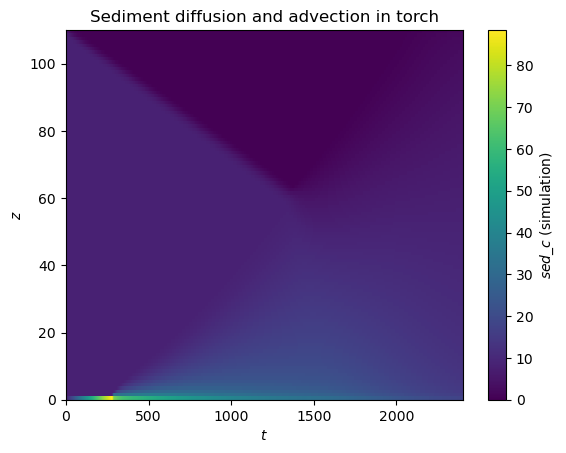

In [ ]:
ds = nc.Dataset(path+'rouse.nc', dtype='float64')
t = ds['time'][:]
z = ds['z'][:].data.squeeze()[0,:]
zi = ds['zi'][:].data.squeeze()[0,:]
sed_c = torch.from_numpy(ds["sed_c"][:].data.squeeze()).to(dtype=torch.float64)

# print("Total error: ", abs_total_error(sed_c, simulation).numpy(), "Abs max error: ", abs_max_error(sed_c, simulation).numpy())
plt.pcolormesh(simulation.squeeze().T)
plt.xlabel('$t$')
plt.ylabel('$z$')
plt.title('Sediment diffusion and advection in torch')
plt.colorbar(label='$sed\_c$ (simulation)')
plt.show()

That looks reasonable! Let's compare it with the actual Fortran output. For that, we calculate the differences:

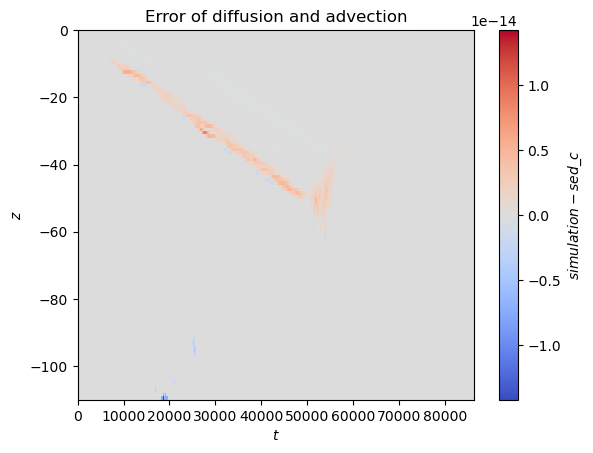

In [ ]:
plt.subplots()
difference = simulation.squeeze().cpu() - sed_c
limit = difference.abs().max()
plt.xlabel('$t$')
plt.ylabel('$z$')
plt.title('Error of diffusion and advection')
plt.pcolormesh(t, z, difference.T, vmin=-limit, vmax=limit, cmap="coolwarm")
plt.colorbar(label='$simulation - sed\_c$')
plt.show()

The errors should have an order of magnitude of $10^{-14}$, which corresponds to numerical double precision.